# Flickr30k CLIP Embedding Analysis

This notebook analyzes the CLIP embeddings generated for the Flickr30k dataset.

Dataset: 31,783 images
Embedding dimension: 512

The analysis includes:
- Embedding validation
- Similarity analysis
- Heatmap visualization
- Embedding distribution
- Visualization of image relationships

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
embeddings = np.load("../artifacts/image_embeddings.npy")

print("Embedding shape:", embeddings.shape)

Embedding shape: (31783, 512)


In [4]:
print("Number of images:", embeddings.shape[0])
print("Embedding dimension:", embeddings.shape[1])
print("Minimum value:", embeddings.min())
print("Maximum value:", embeddings.max())
print("Mean:", embeddings.mean())
print("Standard deviation:", embeddings.std())

Number of images: 31783
Embedding dimension: 512
Minimum value: -0.8110449
Maximum value: 0.43639207
Mean: -0.00079683046
Standard deviation: 0.044186987


In [5]:
sample_size = 500

sample_embeddings = embeddings[:sample_size]

print(sample_embeddings.shape)



(500, 512)


## Calculate similarity

In [7]:
similarity_matrix = np.dot(
    sample_embeddings,
    sample_embeddings.T
)

print(similarity_matrix.shape)

(500, 500)


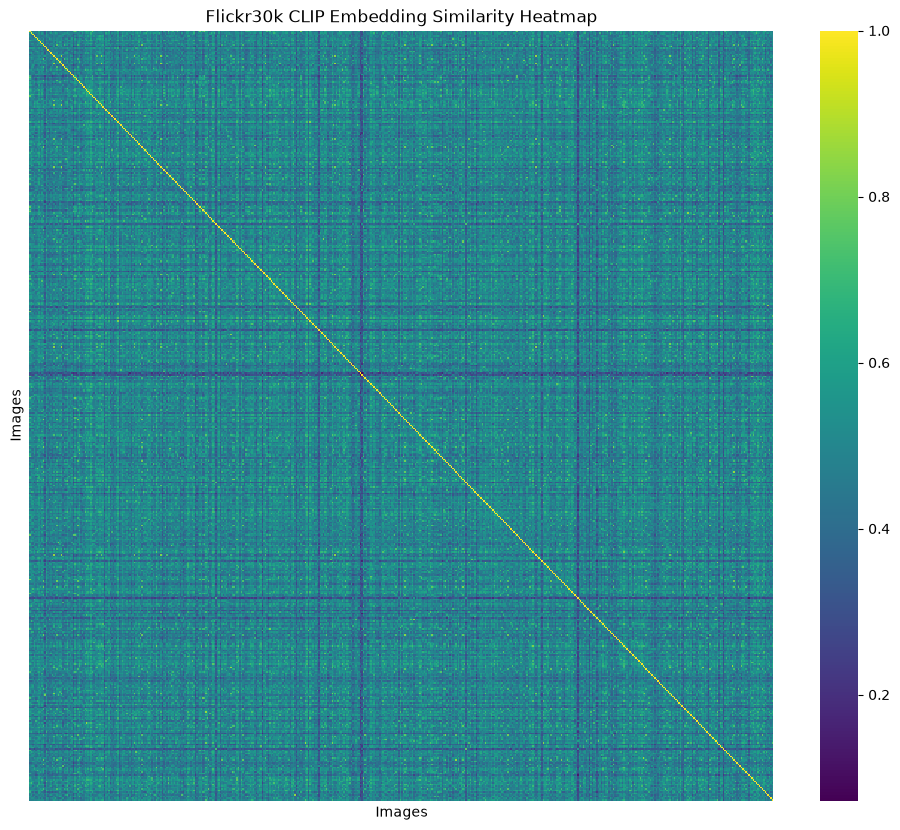

In [13]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    similarity_matrix,
    cmap="viridis",
    xticklabels=False,
    yticklabels=False
)

plt.title("Flickr30k CLIP Embedding Similarity Heatmap")
plt.xlabel("Images")
plt.ylabel("Images")

plt.savefig(
    "../artifacts/flickr30k_similarity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

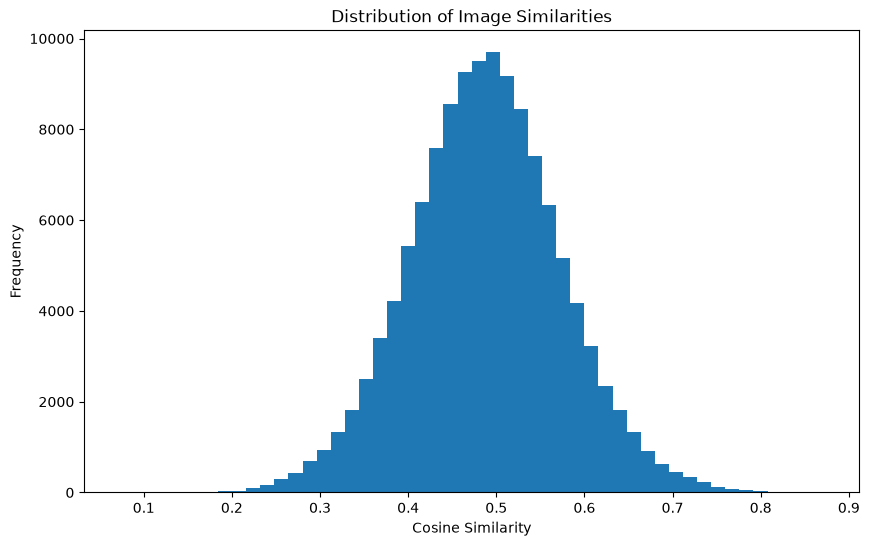

In [14]:
similarities = similarity_matrix[np.triu_indices(
    sample_size,
    k=1
)]

plt.figure(figsize=(10, 6))

plt.hist(similarities, bins=50)

plt.title("Distribution of Image Similarities")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")

plt.savefig(
    "../artifacts/similarity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Analysis of individual images 

In [12]:
image_id = 0

similarities = similarity_matrix[image_id]

top_indices = np.argsort(similarities)[::-1][1:6]

print("Most similar images:")

for idx in top_indices:
    print(
        "Image:", idx,
        "Similarity:", similarities[idx]
    )

Most similar images:
Image: 356 Similarity: 0.8226093
Image: 182 Similarity: 0.79871905
Image: 117 Similarity: 0.78991413
Image: 327 Similarity: 0.78078485
Image: 42 Similarity: 0.77369964


In [16]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Use a sample of embeddings
sample_size = 2000
sample_embeddings = embeddings[:sample_size]

# Reduce 512 dimensions → 2 dimensions
pca = PCA(n_components=2)

reduced_embeddings = pca.fit_transform(sample_embeddings)

print("Original shape:", sample_embeddings.shape)
print("Reduced shape:", reduced_embeddings.shape)

Original shape: (2000, 512)
Reduced shape: (2000, 2)


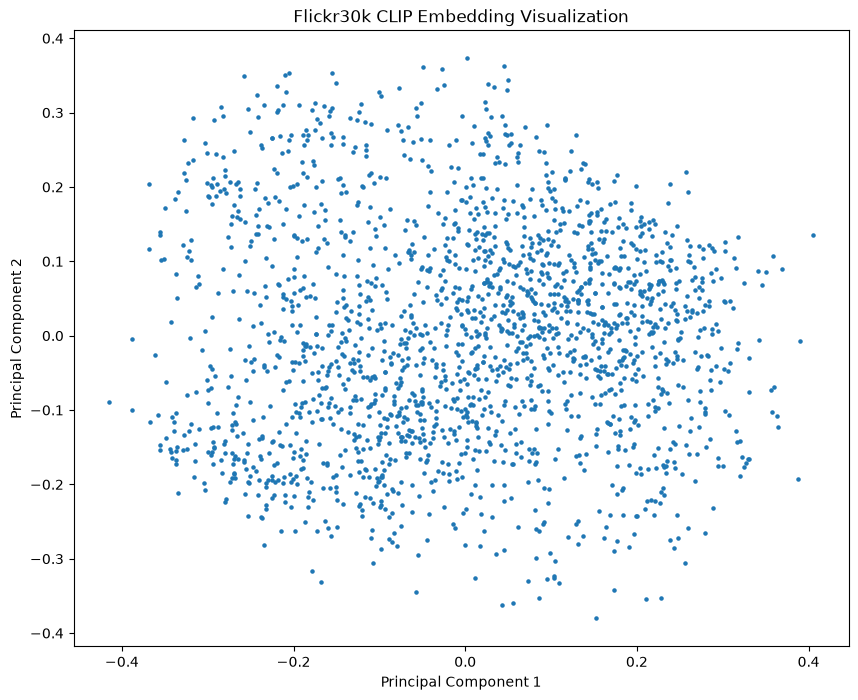

In [17]:
plt.figure(figsize=(10, 8))

plt.scatter(
    reduced_embeddings[:, 0],
    reduced_embeddings[:, 1],
    s=5
)

plt.title("Flickr30k CLIP Embedding Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.savefig(
    "../artifacts/clip_embedding_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()